# 04 · Comparación ampliada, modelo final y despliegue · Dry Bean Dataset
**Rol:** ML Engineer · **Sprint 3** · **Backlog:** PB-05 (comparar métricas) y guardar el modelo con `joblib`

| Fase CRISP-DM | Dónde en este notebook |
|---|---|
| 4–5. Modelado y evaluación | Secciones 2 a 5 |
| 6. Despliegue | Secciones 6 a 8 |

**Por qué existe este notebook.** El diagnóstico del repositorio (bitácora 06) pidió probar formalmente SVM y Gradient Boosting con el mismo protocolo del Sprint 2 antes de dar por cerrada la elección de la regresión logística. Aquí se hace, se decide con la regla del equipo, se entrena y guarda el modelo final y se prueba cargándolo (pasos 16, 17 y 18 del laboratorio).

**Regla de oro (igual que en el notebook 02):** el test no decide nada. La elección usa validación cruzada sobre train.

In [1]:
import os
from pathlib import Path

# El notebook vive en notebooks/; las rutas del proyecto son relativas a la raíz
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import sys
import tempfile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score

from src.error_analysis import confusion_pairs, per_class_metrics
from src.evaluate import (choose_simplest_equivalent, compare_to_reference,
                          min_class_recall, paired_cv_scores, plot_confusion_matrix)
from src.models import COMPLEXITY_ORDER, build_model, load_train_test
from src.predict import (DEFAULT_MODEL_PATH, load_metadata, load_model,
                         predict_bean_class, predict_beans)
from src.predict import main as predict_cli
from src.train import DEFAULT_MODEL, MODEL_FILE, train_final

REPORTS = Path("outputs/reports")
REPORTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Trazabilidad TDSP: versiones con las que se obtuvieron los resultados
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")

Python 3.13.5 | scikit-learn 1.9.1 | pandas 3.1.1


## 1. Datos de entrada
Los mismos `train.csv` y `test.csv` del Sprint 1.

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
assert X_train.shape == (10834, 16) and X_test.shape == (2709, 16)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (10834, 16) | test: (2709, 16)


## 2. Comparación ampliada con el mismo protocolo
Cuatro candidatos, evaluados sobre **los mismos 5 pliegues** estratificados de train (`random_state=42`):

| Modelo | Configuración |
|---|---|
| `logreg` | Baseline del Sprint 2 (escalador + regresión logística) |
| `random_forest` | 200 árboles, `class_weight="balanced"` (Sprint 2) |
| `svm` | SVM RBF; `C` y `gamma` se eligen por `GridSearchCV` **dentro de cada pliegue** (validación cruzada anidada) |
| `hist_gb` | Gradient Boosting; `learning_rate` y `max_iter` por `GridSearchCV` dentro de cada pliegue |

La validación cruzada **anidada** evita el sesgo optimista de elegir hiperparámetros y reportar la misma validación. Tarda varios minutos.

In [3]:
candidatos = {
    "logreg": build_model("logreg"),
    "random_forest": build_model("random_forest"),
    "svm": build_model("svm", tune=True, inner_cv=3, n_jobs=-1),
    "hist_gb": build_model("hist_gb", tune=True, inner_cv=3, n_jobs=-1),
}
puntajes = paired_cv_scores(candidatos, X_train, y_train, cv=5)
puntajes.to_csv(REPORTS / "comparacion_ampliada_por_pliegue.csv")
puntajes.round(4)

,logreg,random_forest,svm,hist_gb
pliegue,,,,
0,0.9377,0.9393,0.9470,0.9435
1,0.9344,0.9325,0.9418,0.9377
2,0.9325,0.9275,0.9348,0.9368
3,0.9346,0.9323,0.9436,0.9392
4,0.9431,0.9398,0.9490,0.9454


In [4]:
tabla = compare_to_reference(puntajes, reference="logreg")
tabla.reset_index().to_csv(REPORTS / "comparacion_ampliada.csv", index=False)
tabla.round(4)

,cv_f1_macro_mean,cv_f1_macro_std,diff_media,diff_std,pliegues_ganados,n_pliegues
modelo,,,,,,
logreg,0.9365,0.0037,0.0000,0.0000,0,5
random_forest,0.9343,0.0047,-0.0022,0.0022,1,5
svm,0.9432,0.0049,0.0068,0.0026,5,5
hist_gb,0.9405,0.0033,0.0041,0.0012,5,5


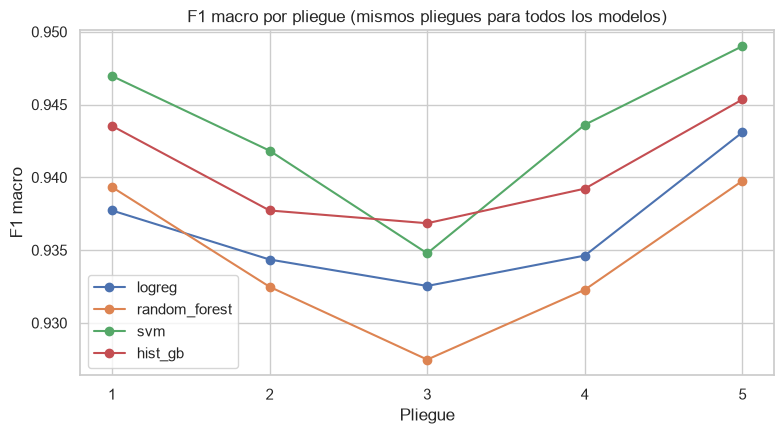

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre in puntajes.columns:
    ax.plot(puntajes.index + 1, puntajes[nombre], marker="o", label=nombre)
ax.set_xticks(range(1, len(puntajes) + 1))
ax.set_xlabel("Pliegue")
ax.set_ylabel("F1 macro")
ax.set_title("F1 macro por pliegue (mismos pliegues para todos los modelos)")
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / "comparacion_ampliada_por_pliegue.png", dpi=150)
plt.show()

## 3. Decisión del modelo final
Misma regla que en el Sprint 2: dos modelos son **equivalentes** si la diferencia de sus medias de CV no supera la mayor de sus dos desviaciones; entre los equivalentes al mejor se elige el **más simple**. El orden de complejidad (de más simple a más complejo) es `logreg` < `svm` < `random_forest` < `hist_gb`.

Además de la regla, la tabla muestra en cuántos de los 5 pliegues cada modelo supera a la regresión logística (`pliegues_ganados`). Con 5 pliegues no es una prueba estadística formal, solo una señal de consistencia.

In [6]:
modelo_final, equivalentes = choose_simplest_equivalent(tabla, COMPLEXITY_ORDER)
mejor = tabla["cv_f1_macro_mean"].idxmax()
print(f"Mejor F1 macro en CV: {mejor} ({tabla.loc[mejor, 'cv_f1_macro_mean']:.4f})")
print("Equivalentes al mejor:", equivalentes)
print("Modelo elegido:", modelo_final)

# El modelo por defecto de `python -m src.train` debe ser el que se decidió aquí
assert modelo_final == DEFAULT_MODEL, (
    f"La decisión ({modelo_final}) no coincide con DEFAULT_MODEL en src/train.py ({DEFAULT_MODEL})")

Mejor F1 macro en CV: svm (0.9432)
Equivalentes al mejor: ['svm', 'hist_gb']
Modelo elegido: svm


## 4. Entrenamiento y guardado del modelo final (paso 16)
`train_final` ajusta los hiperparámetros por validación cruzada de 5 pliegues **solo con train**, evalúa **una vez** en test y guarda el `Pipeline` completo (escalador + clasificador) junto con un JSON de metadata (versiones, hiperparámetros, variables, clases, métricas).

In [7]:
meta = train_final(modelo_final, tune=True, inner_cv=5, n_jobs=-1)
ruta_modelo = DEFAULT_MODEL_PATH
print("Hiperparámetros elegidos:", meta["best_params"])
print(f"F1 macro CV (train): {meta['cv_f1_macro']:.4f}")
m = meta["metrics"]
print(f"Test -> accuracy {m['accuracy']:.4f} | F1 macro {m['f1_macro']:.4f} | "
      f"peor recall {m['min_class_recall']:.3f} ({m['min_recall_class']})")
print(f"Archivo: {ruta_modelo} ({ruta_modelo.stat().st_size / 1024:.0f} KB)")
print("Versiones:", meta["versions"])

Hiperparámetros elegidos: {'classifier__C': 100, 'classifier__gamma': 0.01}
F1 macro CV (train): 0.9437
Test -> accuracy 0.9232 | F1 macro 0.9342 | peor recall 0.871 (SIRA)
Archivo: outputs\models\modelo_final_drybean.joblib (413 KB)
Versiones: {'python': '3.13.5', 'scikit_learn': '1.9.1', 'pandas': '3.1.1', 'numpy': '2.5.4', 'joblib': '1.6.0'}


## 5. Criterio de aceptación y comparación con el baseline en test
Umbrales propuestos en el diagnóstico (a ajustar por el Product Owner): **F1 macro ≥ 0,92** y **recall mínimo por clase ≥ 0,85**. El test se usa aquí solo para informar, no para decidir.

In [8]:
modelo = load_model(ruta_modelo)
y_pred = predict_beans(modelo, X_test)
clase_min, recall_min = min_class_recall(y_test, y_pred)
f1 = meta["metrics"]["f1_macro"]
print(f"F1 macro {f1:.4f} (umbral 0,92): {'CUMPLE' if f1 >= 0.92 else 'NO CUMPLE'}")
print(f"Peor recall {recall_min:.3f} en {clase_min} (umbral 0,85): {'CUMPLE' if recall_min >= 0.85 else 'NO CUMPLE'}")

# Referencia: la regresión logística del Sprint 2, clase por clase
base = build_model("logreg").fit(X_train, y_train)
por_clase = pd.concat({
    "modelo final": per_class_metrics(y_test, y_pred)[["recall", "f1"]],
    "logreg": per_class_metrics(y_test, base.predict(X_test))[["recall", "f1"]],
}, axis=1).round(3)
por_clase

F1 macro 0.9342 (umbral 0,92): CUMPLE
Peor recall 0.871 en SIRA (umbral 0,85): CUMPLE


modelo final        logreg       
                   recall     f1 recall     f1
BARBUNYA            0.913  0.917  0.891  0.908
BOMBAY              1.000  1.000  1.000  1.000
CALI                0.936  0.930  0.942  0.926
DERMASON            0.922  0.920  0.907  0.917
HOROZ               0.938  0.952  0.944  0.954
SEKER               0.956  0.951  0.943  0.938
SIRA                0.871  0.870  0.886  0.872
macro avg           0.934  0.934  0.930  0.931
weighted avg        0.923  0.923  0.920  0.920

## 6. Paso 17 · Cargar el modelo y probar una predicción
Criterio de aceptación del backlog: *el modelo se puede cargar y usar*.

In [9]:
sample = X_test.iloc[[0]]
prediccion = predict_beans(modelo, sample)
print("Predicción:", prediccion[0])
print("Valor real:", y_test.iloc[0])

# El modelo cargado reproduce exactamente las métricas guardadas en la metadata
assert abs(f1 - f1_score(y_test, y_pred, average="macro")) < 1e-12
print("El modelo cargado reproduce el F1 macro registrado en la metadata.")

Predicción: SEKER
Valor real: SEKER
El modelo cargado reproduce el F1 macro registrado en la metadata.


## 7. Paso 18 · Mini despliegue local
`predict_bean_class` valida que estén las 16 variables y devuelve la variedad. También hay una línea de comandos: `python -m src.predict --input nuevos.csv`.

In [10]:
print("Un grano :", predict_bean_class(modelo, sample))
print("Desde dict:", predict_bean_class(modelo, X_test.iloc[0].to_dict()))

# Demo de la CLI con un CSV temporal (no se escribe nada en el repositorio)
with tempfile.TemporaryDirectory() as tmp:
    entrada = Path(tmp) / "nuevos_granos.csv"
    X_test.head(5).to_csv(entrada, index=False)
    predict_cli(["--input", str(entrada), "--model", str(ruta_modelo)])
    display(pd.read_csv(Path(tmp) / "nuevos_granos_predicciones.csv")
            [["Area", "Perimeter", "predicted_class"]])

# La validación rechaza datos incompletos
try:
    predict_beans(modelo, X_test.drop(columns=["Area"]).head(1))
except ValueError as e:
    print("Entrada incompleta rechazada:", e)

Un grano : SEKER
Desde dict: SEKER
5 predicciones guardadas en C:\Users\Jeanp\AppData\Local\Temp\tmp4y3upl21\nuevos_granos_predicciones.csv


,Area,Perimeter,predicted_class
0,40512,737.636,SEKER
1,31890,660.655,DERMASON
2,33107,671.869,DERMASON
3,61684,984.878,HOROZ
4,37189,700.253,SEKER


Entrada incompleta rechazada: Faltan variables en la entrada: ['Area']


## 8. Dónde se equivoca el modelo final

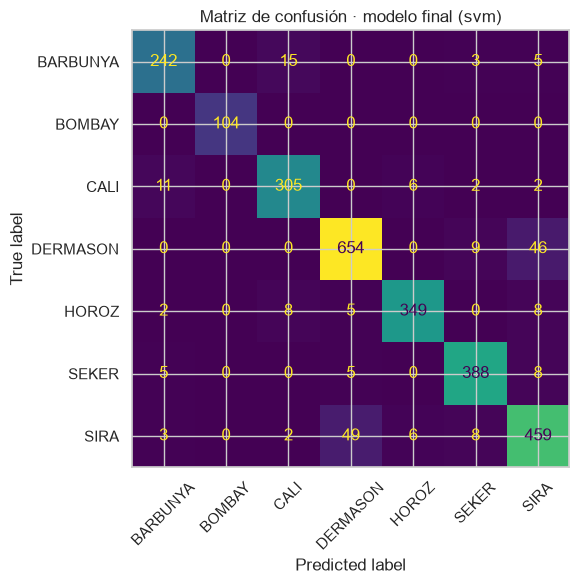

,real,predicho,errores
0,SIRA,DERMASON,49
1,DERMASON,SIRA,46
2,BARBUNYA,CALI,15
3,CALI,BARBUNYA,11
4,DERMASON,SEKER,9
5,HOROZ,CALI,8


In [11]:
fig = plot_confusion_matrix(y_test, y_pred, f"Matriz de confusión · modelo final ({modelo_final})",
                            REPORTS / "matriz_confusion_modelo_final.png")
display(fig)
confusion_pairs(y_test, y_pred, top=6)

### Evidencia por clase para el Product Owner
Reporte por clase y matriz **normalizada por fila** (cada fila suma 1: qué fracción de cada variedad real se clasifica en cada variedad). Es la evidencia que necesita el PO para fijar umbrales por clase, porque `BOMBAY` tiene 104 granos de prueba y `DERMASON` 709.

,precision,recall,f1,support
BARBUNYA,0.920,0.913,0.917,265
BOMBAY,1.000,1.000,1.000,104
CALI,0.924,0.936,0.930,326
DERMASON,0.917,0.922,0.920,709
HOROZ,0.967,0.938,0.952,372
SEKER,0.946,0.956,0.951,406
SIRA,0.869,0.871,0.870,527
macro avg,0.935,0.934,0.934,2709
weighted avg,0.923,0.923,0.923,2709


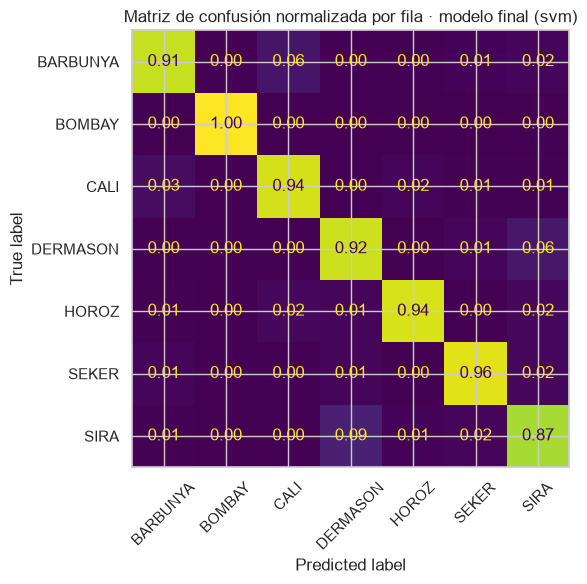

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

por_clase_final = per_class_metrics(y_test, y_pred)
por_clase_final.round(4).to_csv(REPORTS / "metricas_por_clase_modelo_final.csv")
display(por_clase_final.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", values_format=".2f",
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title(f"Matriz de confusión normalizada por fila · modelo final ({modelo_final})")
fig.tight_layout()
fig.savefig(REPORTS / "matriz_confusion_normalizada_modelo_final.png", dpi=150)
plt.show()

## 9. Conclusiones

**Comparación formal (CV anidada de 5 pliegues sobre train)**

| Modelo | F1 macro CV | Diferencia vs. regresión logística | Pliegues ganados |
|---|---|---|---|
| Logistic Regression | 0,9365 ± 0,0037 | — | — |
| Random Forest | 0,9343 ± 0,0047 | −0,0022 | 1 de 5 |
| **SVM RBF** | **0,9432 ± 0,0049** | **+0,0068** | **5 de 5** |
| Gradient Boosting | 0,9405 ± 0,0033 | +0,0041 | 5 de 5 |

**La conclusión del Sprint 2 cambia.** Con la regla del equipo, la regresión logística ya no es equivalente al mejor: la SVM la supera por 0,0068, más que la mayor desviación (0,0049), y gana en los 5 pliegues. Gradient Boosting queda equivalente a la SVM, y entre ambos se elige el más simple: **SVM RBF** (`C=100`, `gamma=0,01`, elegidos por CV de 5 pliegues solo con train).

**Modelo final en test** (se evalúa una sola vez): accuracy 0,9232, F1 macro 0,9342, peor recall 0,871 (`SIRA`). Cumple el criterio propuesto (F1 macro ≥ 0,92 y recall mínimo ≥ 0,85). La regresión logística obtuvo 0,9195, 0,9306 y 0,886.

**Cómo leer la mejora.**
- Es **pequeña pero consistente**: +0,0068 en CV (5 de 5 pliegues) y +0,0036 de F1 macro en test. Un solo split de test no la confirma por sí solo.
- **No arregla el punto débil.** El par `DERMASON` ↔ `SIRA` sigue con 95 errores (la regresión logística tenía 94) y el recall de `SIRA` baja de 0,886 a 0,871. Mejoran otras clases (`BARBUNYA` de 0,891 a 0,913). El límite está en que las clases se solapan en tamaño, no en el algoritmo.

**Limitaciones y decisiones abiertas para el Product Owner**
- `C=100` es el **borde superior de la grilla**: podría haber algo más de margen ampliándola. No se hizo para no seguir buscando sobre los mismos datos.
- La SVM **no es interpretable** como la regresión logística (sin coeficientes por variable) y por defecto no entrega probabilidades. Es una decisión de valor: ≈ 0,7 puntos de F1 en CV a cambio de interpretabilidad.
- Si el PO prefiere interpretabilidad, `python -m src.train --model logreg` reemplaza el modelo guardado sin tocar nada más; el modelo guardado cumple el mismo criterio de aceptación (F1 macro 0,9306 y recall mínimo 0,886).
- Un solo split 80/20 y un solo dataset.

**Despliegue.** El `Pipeline` completo (escalador + SVM) se guardó en `outputs/models/modelo_final_drybean.joblib` (413 KB) con su metadata (versiones, hiperparámetros, variables, clases y métricas). Se cargó, se predijo un grano y el resultado coincide con el valor real y con las métricas registradas. `python -m src.predict` permite predecir un CSV nuevo y rechaza entradas incompletas.